# 01 · Preprocessing — Chen 2021 Prostate (malignant compartment)

Isolate malignant cells, drop spillover-thin samples by a **data-driven multiplicative
gap**, integrate patients (Harmony), embed, and strip physically detached specks. Chen
et al.'s prostate malignant manifold is a **single low-cycling continuous sheet** — there
is no separable cycling/metabolic compartment to remove (unlike Kürten 2021 HNSCC), so
the whole manifold carries the trajectory. Gate 1 asks only that the sheet is *mixed*
(sample-integrated) and *continuous*.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Chen2021_Prostate | category: Prostate


### Load malignant compartment
Chen et al. annotate cell type directly; we take their `Malignant` calls.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Chen2021_Prostate
Done.
full atlas: (36424, 25044)
malignant: (14291, 25044) | samples: 13


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span 25 → 4814. Rather than a round-number cut, we find the
largest **multiplicative** cliff in the sorted counts and cut at its geometric mean — the
natural separatrix between tumour-bearing samples and single-cell spillover. The cliff is
125 → 25 (5×), so the threshold falls at 55 and drops only the 25-cell sample.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [4814 1876 1723 1486 1109 1052  595  436  415  390  245  125   25]
largest gap: 125 -> 25 (ratio 5.00)
derived threshold (geometric mean across the gap) = 55
kept 12/13 samples -> 14266 cells


### Overdispersion, PCA, Harmony integration, embedding
Overdispersed-gene selection (scFates pagoda2 GAM), 50-PC PCA, Harmony on `sample`
(`theta=10`, strong batch mixing without collapsing biology — the Kürten-calibrated
setting), then a 20-PC neighbour graph and UMAP (`spread=1.3`).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('embedded:', adata.shape)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1583 over-dispersed features (0:00:04) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1583
embedded: (14266, 21974)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous sheet intact.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape)

removed 0 cells in 0 detached islands
after island removal: (14266, 21974)


### No cycling/metabolic compartment to split (data-driven)
Kürten's HNSCC manifold split into a low-cycling *Embryonic* lobe and a *Cycling/Metabolic*
lobe, and only the former carried the trajectory. Here we test the same question: a
low-resolution Leiden (res=0.15) recovers two lobes, but **both are uniformly low-cycling**
(overall cycling fraction ≈ 0.02) — there is no cycling compartment to strip. The manifold
is a single continuous sheet, so the **whole** malignant manifold enters the trajectory.

In [7]:
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('overall cycling fraction:', round(adata.obs['cycling'].mean(), 3))
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('-> both lobes low-cycling; no separable cycling compartment; whole manifold carries the trajectory.')

overall cycling fraction: 0.021
lobe sizes: {'0': 7557, '1': 6709}
cycling fraction per lobe: {'0': 0.028, '1': 0.013}
-> both lobes low-cycling; no separable cycling compartment; whole manifold carries the trajectory.


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. Below: UMAP
coloured by `sample` (integration) and `cell_cycle_phase` (the uniform low-cycling field).

12 samples share one continuous manifold; 14266 cells, single connected component.
Gate 1: samples intermixed on one continuous manifold, no per-patient islands -> GO


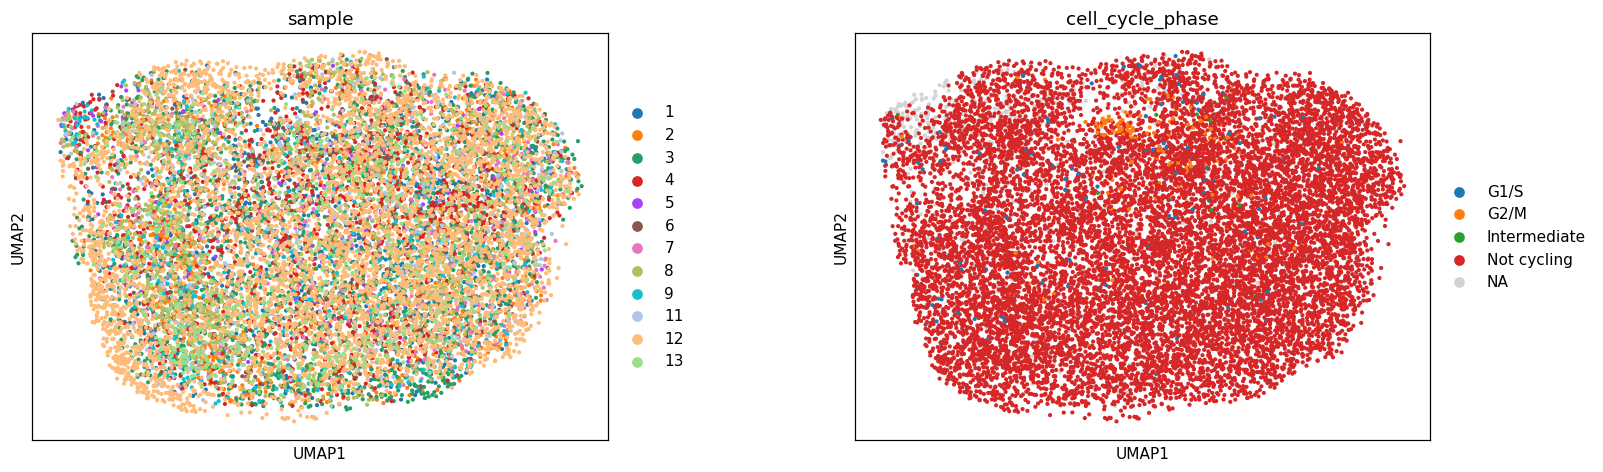

In [8]:
fig = sc.pl.umap(adata, color=['sample','cell_cycle_phase'], size=30, wspace=.3,
                 show=False, return_fig=True)
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; {adata.shape[0]} cells, single connected component.')
print('Gate 1: samples intermixed on one continuous manifold, no per-patient islands -> GO')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (14266, 21974)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, coloured by `sample`.
Orientation matches the fixed pseudotime convention set in 02 (raw x is the trajectory
axis here, so a single x-flip gives left→right); direction is immaterial for this
categorical panel. Intermixing across the strip is the Gate-1 batch-integration evidence.

saved samples.pdf | manifold cells: 14266


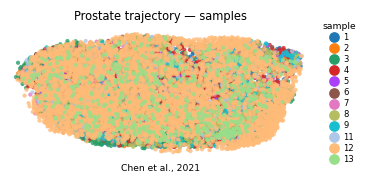

In [10]:
traj = adata.copy()
xy = traj.obsm['X_umap'].astype(float)
traj.obsm['X_umap'] = np.column_stack([-xy[:,0], xy[:,1]])   # x-flip (no swap): raw x is the trajectory axis
xl = traj.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(traj, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Prostate trajectory — samples', size=7.5)
ax.text(.5, -.12, 'Chen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | manifold cells:', traj.shape[0])